# MOP 3231 · Task 2 — Decision Trees: Entropy, Over-fitting and a Logistic Regression Comparison

**Student:** Imamsidikov · **Dataset:** `data/heart_disease.csv` (Cleveland subset of UCI Heart Disease, 297 patients, CC BY 4.0)

| Part | Topic |
|---|---|
| 0 | Setup, versions, SEED, load and split |
| 1 | Entropy and information gain by hand |
| 2 | A decision tree from scratch (NumPy) and a check against scikit-learn |
| 3 | How deep should the tree be? |
| 4 | Tree or logistic regression? |
| 5 | Reading a tree, and reproducibility |

This is a teaching dataset, not clinical evidence: no medical conclusions are drawn from it.

## Part 0 · Setup

Virtual environment `.Imamsidikov_ML_task_2` (Python 3.12) with the pinned `requirements.txt`; Jupyter is only the tool and stays out of it.

**SEED = 2954**: the last four digits of my student ID (S24072954). It seeds the train/test split and the cross-validation folds.

In [1]:
import sys

import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__)

3.12.12 2.0.2 2.3.3 1.6.1


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 2954

data = pd.read_csv("data/heart_disease.csv")
feature_names = [c for c in data.columns if c != "disease"]
X, y = data[feature_names].to_numpy(), data["disease"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
print(data.shape, round(y.mean(), 3), X_train.shape, X_test.shape)

(297, 14) 0.461 (207, 13) (90, 13)


## Part 1 · Entropy and information gain by hand

Twelve synthetic patients (6 with disease, 6 without), four yes/no features.
$H = -\sum_c p_c \log_2 p_c$, and $IG = H(\text{parent}) - \sum_k \frac{n_k}{n} H(\text{child}_k)$.

Entropies used below (computed once):
- $H(\tfrac12,\tfrac12) = 1$
- $H(\tfrac56,\tfrac16) = -\tfrac56\log_2\tfrac56 - \tfrac16\log_2\tfrac16 = 0.2192 + 0.4308 = 0.6500$
- $H(\tfrac23,\tfrac13) = -\tfrac23\log_2\tfrac23 - \tfrac13\log_2\tfrac13 = 0.3900 + 0.5283 = 0.9183$
- $H(\tfrac14,\tfrac34) = -\tfrac14\log_2\tfrac14 - \tfrac34\log_2\tfrac34 = 0.5000 + 0.3113 = 0.8113$
- $H(\tfrac25,\tfrac35) = -\tfrac25\log_2\tfrac25 - \tfrac35\log_2\tfrac35 = 0.5288 + 0.4422 = 0.9710$
- $H(\tfrac15,\tfrac45) = -\tfrac15\log_2\tfrac15 - \tfrac45\log_2\tfrac45 = 0.4644 + 0.2575 = 0.7219$
- a pure node has $H = 0$ (using $0\cdot\log_2 0 = 0$)

### 1. Parent entropy

6 yes, 6 no out of 12:
$$H(\text{parent}) = -\tfrac{6}{12}\log_2\tfrac{6}{12} - \tfrac{6}{12}\log_2\tfrac{6}{12} = 0.5 + 0.5 = \mathbf{1.000 \text{ bit}}$$

### 2. Root: gain of each feature (all 12 patients)

| Feature | value = 1 (yes / no) | value = 0 (yes / no) | Weighted child entropy | Gain |
|---|---|---|---|---|
| age_55_plus | p1–p5, p7: 5 / 1 → 0.6500 | p6, p8–p12: 1 / 5 → 0.6500 | $\tfrac{6}{12}0.6500 + \tfrac{6}{12}0.6500 = 0.6500$ | $1 - 0.6500 = \mathbf{0.3500}$ |
| exercise_angina | p1–p4: 4 / 0 → 0 | p5–p12: 2 / 6 → 0.8113 | $\tfrac{4}{12}\cdot 0 + \tfrac{8}{12}0.8113 = 0.5409$ | $1 - 0.5409 = \mathbf{0.4591}$ |
| male | p1–p3, p7–p9: 3 / 3 → 1 | p4–p6, p10–p12: 3 / 3 → 1 | $\tfrac{6}{12}\cdot 1 + \tfrac{6}{12}\cdot 1 = 1$ | $1 - 1 = \mathbf{0.0000}$ |
| high_bp | p1, p2, p4, p5, p10, p11: 4 / 2 → 0.9183 | p3, p6–p9, p12: 2 / 4 → 0.9183 | $\tfrac{6}{12}0.9183 + \tfrac{6}{12}0.9183 = 0.9183$ | $1 - 0.9183 = \mathbf{0.0817}$ |

**Root: `exercise_angina`** (gain 0.4591). Its "yes" branch (p1–p4) is pure: all four have the disease.

### 3. One level down: the impure branch `exercise_angina = 0`

Patients p5–p12: 2 yes (p5, p6), 6 no → $H = H(\tfrac14,\tfrac34) = 0.8113$.

| Feature | value = 1 (yes / no) | value = 0 (yes / no) | Weighted child entropy | Gain |
|---|---|---|---|---|
| age_55_plus | p5, p7: 1 / 1 → 1 | p6, p8–p12: 1 / 5 → 0.6500 | $\tfrac{2}{8}\cdot 1 + \tfrac{6}{8}0.6500 = 0.7375$ | $0.8113 - 0.7375 = \mathbf{0.0738}$ |
| male | p7, p8, p9: 0 / 3 → 0 | p5, p6, p10–p12: 2 / 3 → 0.9710 | $\tfrac{3}{8}\cdot 0 + \tfrac{5}{8}0.9710 = 0.6069$ | $0.8113 - 0.6069 = \mathbf{0.2044}$ |
| high_bp | p5, p10, p11: 1 / 2 → 0.9183 | p6–p9, p12: 1 / 4 → 0.7219 | $\tfrac{3}{8}0.9183 + \tfrac{5}{8}0.7219 = 0.7956$ | $0.8113 - 0.7956 = \mathbf{0.0157}$ |

**`male` is chosen** inside this branch with gain 0.2044, although at the root its gain was exactly 0.

**Why:** at the root, `male` splits the 12 patients into two 3/3 halves, because its effect is cancelled by the
four angina patients (three of whom are male). Once the root has removed those patients, the rest are not mixed the same way:
all three remaining men are healthy, so `male` now separates the classes well. Information gain measures a feature *given
the splits above it*, so a feature that is useless on its own can become the best choice inside a branch.

In [3]:
# The same numbers as arithmetic, to check the hand calculations above
from math import log2

def H(*counts):
    n = sum(counts)
    return -sum(c / n * log2(c / n) for c in counts if c > 0)

parent = H(6, 6)
root_gains = {
    "age_55_plus": parent - (6 / 12 * H(5, 1) + 6 / 12 * H(1, 5)),
    "exercise_angina": parent - (4 / 12 * H(4, 0) + 8 / 12 * H(2, 6)),
    "male": parent - (6 / 12 * H(3, 3) + 6 / 12 * H(3, 3)),
    "high_bp": parent - (6 / 12 * H(4, 2) + 6 / 12 * H(2, 4)),
}
branch = H(2, 6)
branch_gains = {
    "age_55_plus": branch - (2 / 8 * H(1, 1) + 6 / 8 * H(1, 5)),
    "male": branch - (3 / 8 * H(0, 3) + 5 / 8 * H(2, 3)),
    "high_bp": branch - (3 / 8 * H(1, 2) + 5 / 8 * H(1, 4)),
}
print(f"parent entropy = {parent:.4f}")
print("root gains:  ", {k: round(v, 4) for k, v in root_gains.items()})
print(f"branch entropy (exercise_angina = 0) = {branch:.4f}")
print("branch gains:", {k: round(v, 4) for k, v in branch_gains.items()})

parent entropy = 1.0000
root gains:   {'age_55_plus': 0.35, 'exercise_angina': 0.4591, 'male': 0.0, 'high_bp': 0.0817}
branch entropy (exercise_angina = 0) = 0.8113
branch gains: {'age_55_plus': 0.0738, 'male': 0.2044, 'high_bp': 0.0157}


## Part 2 · A decision tree from scratch

The learning algorithm from the lecture in NumPy. Rules followed:
- candidate thresholds are midpoints between consecutive distinct sorted values; rows with `x <= threshold` go left;
- a split is valid only if both children have at least `min_samples_leaf` rows; ties between equal gains go to the lower
  feature index, then the lower threshold (features and thresholds are scanned in increasing order and only a *strictly*
  larger gain replaces the current best);
- a node becomes a leaf when it is pure, when `depth == max_depth`, or when no valid split exists; a leaf predicts its majority
  class, a tie going to the smaller label (`np.argmax` returns the first maximum).

In [4]:
def entropy(y):
    """Entropy in bits of an array of integer class labels."""
    y = np.asarray(y)
    if y.size == 0:
        return 0.0
    p = np.bincount(y) / y.size
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def information_gain(y, left):
    """Entropy of y minus the size-weighted entropy of y[left] and y[~left]; left is a boolean mask."""
    y, left = np.asarray(y), np.asarray(left, dtype=bool)
    n, n_left = y.size, left.sum()
    return entropy(y) - n_left / n * entropy(y[left]) - (n - n_left) / n * entropy(y[~left])


def best_split(X, y, min_samples_leaf=1):
    """Return (feature_index, threshold, gain) of the best split, or None if no valid split exists."""
    best = None
    n = len(y)
    for j in range(X.shape[1]):
        values = np.unique(X[:, j])
        for threshold in (values[:-1] + values[1:]) / 2:
            left = X[:, j] <= threshold
            n_left = left.sum()
            if n_left < min_samples_leaf or n - n_left < min_samples_leaf:
                continue
            gain = information_gain(y, left)
            if best is None or gain > best[2] + 1e-12:  # strictly better; tolerance absorbs float noise
                best = (j, float(threshold), gain)
    return best


def build_tree(X, y, max_depth=None, min_samples_leaf=1, depth=0):
    """Grow a tree recursively and return it as nested dicts (or any structure you like)."""
    counts = np.bincount(y, minlength=2)
    leaf = {"leaf": True, "label": int(np.argmax(counts)), "n": len(y), "counts": counts.tolist()}
    if counts.max() == len(y) or (max_depth is not None and depth == max_depth):
        return leaf
    split = best_split(X, y, min_samples_leaf)
    if split is None:
        return leaf
    j, threshold, gain = split
    left = X[:, j] <= threshold
    return {
        "leaf": False, "feature": j, "threshold": threshold, "gain": gain, "n": len(y),
        "left": build_tree(X[left], y[left], max_depth, min_samples_leaf, depth + 1),
        "right": build_tree(X[~left], y[~left], max_depth, min_samples_leaf, depth + 1),
    }


def predict_tree(tree, X):
    """Return one predicted label per row of X."""
    def predict_row(node, row):
        while not node["leaf"]:
            node = node["left"] if row[node["feature"]] <= node["threshold"] else node["right"]
        return node["label"]
    return np.array([predict_row(tree, row) for row in X])


def n_leaves(tree):
    """Number of leaves of a tree built by build_tree."""
    return 1 if tree["leaf"] else n_leaves(tree["left"]) + n_leaves(tree["right"])

In [5]:
# Sanity check: an unlimited tree is consistent with the training data (no two identical rows with different labels)
tree_full = build_tree(X_train, y_train)
print("leaves:", n_leaves(tree_full), "| training accuracy:", (predict_tree(tree_full, X_train) == y_train).mean())

# min_samples_leaf is respected: no leaf smaller than 10 rows
def leaf_sizes(tree):
    return [tree["n"]] if tree["leaf"] else leaf_sizes(tree["left"]) + leaf_sizes(tree["right"])

print("smallest leaf with min_samples_leaf=10:", min(leaf_sizes(build_tree(X_train, y_train, min_samples_leaf=10))))

leaves: 33 | training accuracy: 1.0
smallest leaf with min_samples_leaf=10: 10


### Check against scikit-learn

**Q1.** `entropy` and `information_gain` on the toy table of Part 1:

In [6]:
toy = pd.DataFrame({
    "age_55_plus": [1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0],
    "exercise_angina": [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
    "male": [1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0],
    "high_bp": [1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0],
    "disease": [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
})
toy_features = ["age_55_plus", "exercise_angina", "male", "high_bp"]
ty = toy["disease"].to_numpy()

print(f"parent entropy: code {entropy(ty):.4f} | hand {parent:.4f}")
rows = []
for f in toy_features:
    rows.append({"node": "root", "feature": f, "code": information_gain(ty, toy[f].to_numpy() == 1), "hand": root_gains[f]})
inner = toy[toy["exercise_angina"] == 0]
for f in ["age_55_plus", "male", "high_bp"]:
    rows.append({"node": "exercise_angina = 0", "feature": f,
                 "code": information_gain(inner["disease"].to_numpy(), inner[f].to_numpy() == 1), "hand": branch_gains[f]})
check = pd.DataFrame(rows).round(4)
check["match"] = np.isclose(check["code"], check["hand"], atol=1e-4)
print(check.to_string(index=False))
print("best_split on the toy table:", best_split(toy[toy_features].to_numpy(), ty))

parent entropy: code 1.0000 | hand 1.0000
               node         feature   code   hand  match
               root     age_55_plus 0.3500 0.3500   True
               root exercise_angina 0.4591 0.4591   True
               root            male 0.0000 0.0000   True
               root         high_bp 0.0817 0.0817   True
exercise_angina = 0     age_55_plus 0.0738 0.0738   True
exercise_angina = 0            male 0.2044 0.2044   True
exercise_angina = 0         high_bp 0.0157 0.0157   True
best_split on the toy table: (1, 0.5, np.float64(0.4591479170272448))


**Q2.** Root split of my `best_split` against scikit-learn on `X_train, y_train`:

In [7]:
from sklearn.tree import DecisionTreeClassifier

ref = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=SEED).fit(X_train, y_train)
print("scikit-learn:", feature_names[ref.tree_.feature[0]], ref.tree_.threshold[0])

j, threshold, gain = best_split(X_train, y_train)
print(f"my best_split: {feature_names[j]} {threshold} (gain {gain:.4f})")

scikit-learn: cp 3.5
my best_split: cp 3.5 (gain 0.2333)


**Q3.** Fraction of test rows on which my tree and scikit-learn's (`criterion="entropy"`, same depth, `random_state=SEED`) agree:

In [8]:
agreement = []
for depth in [1, 2, 3, 4, 5, None]:
    mine = build_tree(X_train, y_train, max_depth=depth)
    sk = DecisionTreeClassifier(criterion="entropy", max_depth=depth, random_state=SEED).fit(X_train, y_train)
    agreement.append({
        "max_depth": "unlimited" if depth is None else depth,
        "leaves (mine)": n_leaves(mine),
        "leaves (sklearn)": sk.get_n_leaves(),
        "test agreement": (predict_tree(mine, X_test) == sk.predict(X_test)).mean(),
    })
agreement = pd.DataFrame(agreement)
print(agreement.round(3).to_string(index=False))

max_depth  leaves (mine)  leaves (sklearn)  test agreement
        1              2                 2           1.000
        2              4                 4           1.000
        3              8                 8           1.000
        4             15                15           0.944
        5             23                23           0.944
unlimited             33                34           0.922


**Answers.**
1. Yes. `entropy` gives 1.0000 for the 12 patients, and `information_gain` reproduces all seven hand gains to four decimals
   (0.3500 / 0.4591 / 0.0000 / 0.0817 at the root; 0.0738 / 0.2044 / 0.0157 inside `exercise_angina = 0`).
   `best_split` on the toy table picks feature 1 (`exercise_angina`).
2. Yes. Both choose **`cp <= 3.5`** at the root (gain 0.2333 bits): asymptomatic chest pain (`cp = 4`) against the other three types.
3. The trees agree on 100% of the test rows for depths 1–3. At depth 4 and 5 they agree on 94.4%, and unlimited on 92.2%.

**Why the agreement falls below 100% at depth ≥ 4:** every place where the two trees part is a node where two
different splits have *exactly the same* information gain. For example, in a 6-row node my `sex <= 0.5` and scikit-learn's
`thalach <= 159.5` both gain 0.3167 bits, and in a 28-row node `chol <= 279.5` and `ca <= 1.5` both gain 0.1435.
My rule gives the tie to the lower feature index. scikit-learn visits the features in a random order (drawn from
`random_state`) and keeps the first best one, so it can pick another feature. The training fit is the same, but the
leaves cover different regions, so a few test rows that fall between them get a different label. The extra leaf of the unlimited
scikit-learn tree (34 against 33) comes from the same cause: a different tie choice higher up leaves differently-sized impure nodes below.

## Part 3 · How deep should the tree be?

All of 3a–3d use **only the training split** (207 rows) with 5 stratified folds seeded with SEED. The test split is used once, in 3e.

### 3a. Depth sweep
Per depth: number of leaves (mean of the 5 fold models), mean training accuracy, mean CV accuracy and the std of CV accuracy over the folds.

In [9]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def sweep(param, values, **fixed):
    rows = []
    for v in values:
        model = DecisionTreeClassifier(criterion="entropy", random_state=SEED, **{param: v}, **fixed)
        s = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy",
                           return_train_score=True, return_estimator=True)
        rows.append({
            param: "None" if v is None else v,
            "leaves (mean over folds)": np.mean([e.get_n_leaves() for e in s["estimator"]]),
            "train acc": s["train_score"].mean(),
            "CV acc": s["test_score"].mean(),
            "CV std": s["test_score"].std(),
        })
    return pd.DataFrame(rows)

depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
depth_table = sweep("max_depth", depths)
print(depth_table.round(3).to_string(index=False))

max_depth  leaves (mean over folds)  train acc  CV acc  CV std
        1                       2.0      0.787   0.715   0.052
        2                       4.0      0.792   0.691   0.049
        3                       7.8      0.855   0.749   0.070
        4                      13.4      0.920   0.725   0.035
        5                      19.4      0.955   0.705   0.026
        6                      23.4      0.987   0.696   0.018
        8                      25.4      0.998   0.705   0.035
       10                      25.8      1.000   0.700   0.039
     None                      25.8      1.000   0.700   0.039


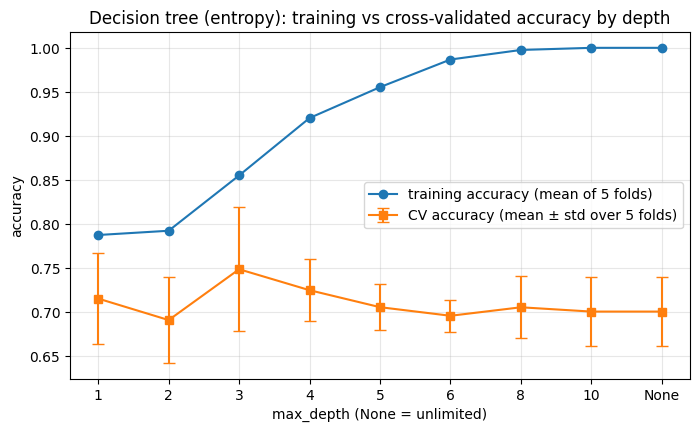

In [10]:
labels = [str(d) for d in depth_table["max_depth"]]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, depth_table["train acc"], "o-", label="training accuracy (mean of 5 folds)")
ax.errorbar(x, depth_table["CV acc"], yerr=depth_table["CV std"], fmt="s-", capsize=4,
            label="CV accuracy (mean ± std over 5 folds)")
ax.set_xticks(x, labels)
ax.set_xlabel("max_depth (None = unlimited)")
ax.set_ylabel("accuracy")
ax.set_title("Decision tree (entropy): training vs cross-validated accuracy by depth")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### 3b. Plot (above) and 3c. Selection rule

**Rule (one-standard-error rule):** find the depth with the highest mean CV accuracy and compute the standard error of that
mean, $SE = \text{std over folds} / \sqrt{5}$. Every depth whose mean CV accuracy is within one SE of the best one counts as
equally good. Among them, pick the **shallowest** tree, because it is the simplest. The rule uses the fold spread: a depth
only "wins" if it beats the others by more than the noise between folds.

In [11]:
best = depth_table["CV acc"].idxmax()
se_best = depth_table.loc[best, "CV std"] / np.sqrt(cv.get_n_splits())  # standard error of the 5-fold mean
threshold = depth_table.loc[best, "CV acc"] - se_best
candidates = depth_table[depth_table["CV acc"] >= threshold]
chosen = candidates.iloc[0]  # depths are listed from shallow to deep, so the first is the simplest
CHOSEN_DEPTH = None if chosen["max_depth"] == "None" else int(chosen["max_depth"])
print(f"best mean CV: max_depth={depth_table.loc[best, 'max_depth']} "
      f"({depth_table.loc[best, 'CV acc']:.3f}, std {depth_table.loc[best, 'CV std']:.3f}, SE {se_best:.3f}) -> bar = {threshold:.3f}")
print("depths within one SE of the best:", list(candidates["max_depth"]))
print("chosen max_depth:", CHOSEN_DEPTH)

best mean CV: max_depth=3 (0.749, std 0.070, SE 0.031) -> bar = 0.717
depths within one SE of the best: [3, 4]
chosen max_depth: 3


**Result: max_depth = 3.** Depth 3 has the best mean CV accuracy (0.749, std 0.070, SE 0.031), so the bar is 0.717.
Only depths 3 and 4 (0.725) clear it, and 3 is the shallower one. Depth 1 (0.715) misses the bar by 0.002.

**Is depth 3 clearly better than its neighbours? No.** Depth 4 is 0.024 behind, which is less than one SE. Depth 2 (0.691) is
0.058 behind, which is within one fold std (0.070). The single-fold accuracies of depths 1–6 overlap heavily. What is clear is
only the shape of the curve: training accuracy climbs to 1.000 while CV accuracy stops improving after depth 3.

### 3d. A second brake: `min_samples_leaf` (unlimited depth)

In [12]:
msl_table = sweep("min_samples_leaf", [1, 2, 5, 10, 20, 40], max_depth=None)
print(msl_table.round(3).to_string(index=False))

 min_samples_leaf  leaves (mean over folds)  train acc  CV acc  CV std
                1                      25.8      1.000   0.700   0.039
                2                      23.6      0.955   0.710   0.042
                5                      16.0      0.911   0.725   0.053
               10                      10.2      0.861   0.744   0.069
               20                       6.0      0.796   0.725   0.061
               40                       3.0      0.787   0.715   0.052


**Comparison of the two brakes.** Both reach about the same best CV accuracy: `min_samples_leaf = 10` gives 0.744 ± 0.069
with about 10 leaves, against 0.749 ± 0.070 with about 8 leaves for `max_depth = 3`, a difference far inside the noise.
`max_depth` cuts every branch at the same depth however many patients it holds. `min_samples_leaf` lets
branches with many patients go deeper and stops branches with few, so it limits the tree by the amount of evidence rather than by
a fixed number of questions.

### 3e. Test once
The chosen model (`max_depth = 3`) is fitted on the full training split and scored on the test split exactly once.

In [13]:
final_tree = DecisionTreeClassifier(criterion="entropy", max_depth=CHOSEN_DEPTH, random_state=SEED).fit(X_train, y_train)
p = (final_tree.predict(X_test) == y_test).mean()
se = np.sqrt(p * (1 - p) / len(y_test))
print(f"test accuracy (max_depth={CHOSEN_DEPTH}) = {p:.3f} ± {se:.3f} (standard error, n = {len(y_test)})")

test accuracy (max_depth=3) = 0.844 ± 0.038 (standard error, n = 90)


**Test accuracy = 0.844 ± 0.038** (SE $= \sqrt{p(1-p)/n} = \sqrt{0.844 \cdot 0.156 / 90}$). This is higher than the 0.749 CV
estimate. With only 90 test rows (SE 0.038) and a fold std of 0.070, the gap is consistent with a lucky test split; it does not show
that the tree is better than CV suggested.

**The gap at `max_depth=None`:** training accuracy is 1.000 but CV accuracy is 0.700. A 30-point gap means the unlimited tree
memorises the training patients, noise included, and that does not carry over to new patients. It is over-fitting.

## Part 4 · Tree or logistic regression?

### 4a. Cross-validation on the same folds `cv`
The scaler for logistic regression sits inside a pipeline, so it is fitted on each training fold only.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    f"tree max_depth={CHOSEN_DEPTH}": DecisionTreeClassifier(criterion="entropy", max_depth=CHOSEN_DEPTH, random_state=SEED),
    "tree unlimited": DecisionTreeClassifier(criterion="entropy", max_depth=None, random_state=SEED),
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
}
cv_rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=("accuracy", "f1"))
    cv_rows.append({"model": name, "CV acc mean": s["test_accuracy"].mean(), "CV acc std": s["test_accuracy"].std(),
                    "CV F1 mean": s["test_f1"].mean(), "fold accs": np.round(s["test_accuracy"], 3).tolist()})
cv_table = pd.DataFrame(cv_rows)
print(cv_table.round(3).to_string(index=False))

              model  CV acc mean  CV acc std  CV F1 mean                           fold accs
   tree max_depth=3        0.749       0.070       0.713 [0.833, 0.714, 0.805, 0.756, 0.634]
     tree unlimited        0.700       0.039       0.675 [0.738, 0.667, 0.756, 0.659, 0.683]
logistic regression        0.817       0.073       0.791  [0.786, 0.738, 0.78, 0.951, 0.829]


### 4b. Does a tree need scaling?

In [15]:
scaler = StandardScaler().fit(X_train)
tree_raw = DecisionTreeClassifier(criterion="entropy", max_depth=CHOSEN_DEPTH, random_state=SEED).fit(X_train, y_train)
tree_scaled = DecisionTreeClassifier(criterion="entropy", max_depth=CHOSEN_DEPTH, random_state=SEED).fit(
    scaler.transform(X_train), y_train)
same = (tree_raw.predict(X_test) == tree_scaled.predict(scaler.transform(X_test))).mean()
print(f"test rows with the same prediction: {same:.3f}")
print("same features used at the nodes:", np.array_equal(tree_raw.tree_.feature, tree_scaled.tree_.feature))

test rows with the same prediction: 1.000
same features used at the nodes: True


**Agreement: 100% of the test rows (90 / 90), and the same features are used at every node.** Standardisation
$x \mapsto (x - \mu)/\sigma$ is an increasing linear map applied to each feature separately, so it keeps the *order* of the
values within each feature. A tree split only asks "is $x_j$ below a threshold?", so the same rows go left and right, every
candidate split has the same information gain, and the same split wins. Only the threshold number changes: it is mapped to
the scaled units, and the midpoints of the scaled values are the scaled midpoints. A tree therefore does not need scaling. Logistic
regression does, because its coefficients and its regularisation depend on the units.

### 4c. Hold-out, once
Both models are fitted on the full training split and scored on the test split.

In [16]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_train, y_train)
holdout = []
for name, model in [(f"tree max_depth={CHOSEN_DEPTH}", final_tree), ("logistic regression", logreg)]:
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    holdout.append({"model": name, "test acc": acc, "SE": np.sqrt(acc * (1 - acc) / len(y_test)),
                    "test F1": f1_score(y_test, pred)})
    print(name, "confusion matrix (rows = true 0/1, columns = predicted 0/1):")
    print(confusion_matrix(y_test, pred), "\n")
print(pd.DataFrame(holdout).round(3).to_string(index=False))

tree max_depth=3 confusion matrix (rows = true 0/1, columns = predicted 0/1):
[[42  6]
 [ 8 34]] 

logistic regression confusion matrix (rows = true 0/1, columns = predicted 0/1):
[[42  6]
 [ 7 35]] 

              model  test acc    SE  test F1
   tree max_depth=3     0.844 0.038    0.829
logistic regression     0.856 0.037    0.843


### 4d. Conclusion

| | CV acc (mean ± std) | CV F1 | Test acc ± SE | Test F1 |
|---|---|---|---|---|
| tree, max_depth = 3 | 0.749 ± 0.070 | 0.713 | 0.844 ± 0.038 | 0.829 |
| tree, unlimited | 0.700 ± 0.039 | 0.675 | — | — |
| logistic regression | 0.817 ± 0.073 | 0.791 | 0.856 ± 0.037 | 0.843 |

I would use **logistic regression**, but only with moderate confidence. In CV it leads the depth-3 tree by 0.068 accuracy and 0.078 F1. That is about one fold std (0.07), and it wins in only 3 of the 5 folds, so the lead is suggestive, not decisive.
On the test split the two are **indistinguishable**: 0.856 against 0.844 is one patient out of 90 (the confusion matrices differ in a single false negative), far inside an SE of 0.037–0.038.
The depth-3 tree against the unlimited tree (0.749 against 0.700 in CV) is also within one fold std, so I cannot say from these numbers that pruning helps by a definite amount.
What tips the choice is that logistic regression has the higher mean on every metric and needs no depth tuning, while the tree's advantage is that it is readable (Part 5).